# Diagnóstico dos erros do exp15 (YOLO11l + Optuna, melhor mAP50 até agora)

- Autor: Clésio Gonçalves
- Criado em: 18 nov. 2026

**Objetivo:** antes de escolher uma técnica de pré-processamento, entender **que tipo de erro** o detector comete e em quais leishmanias. Usa os 6 modelos do exp15 (melhor mAP50 da série, 0,510) (cada um nas 2 lâminas de teste do seu fold), sem treinar nada.

**Como:**
1. predição em todos os recortes de teste (GPU, confiança mínima 0,05);
2. escolha do limiar de confiança de maior F1;
3. casamento predição × anotação com IoU ≥ 0,5 (o mesmo critério do mAP50);
4. medidas de cada caixa: tamanho, contraste local, canal de hematoxilina (H), distância até a máscara preta, borda do recorte, coincidência com anotações `inside-macrophage` originais;
5. classificação de cada erro e galerias de exemplos.

As figuras vão para `figuras/` e a lista de falsos positivos de confiança alta (candidatos a anotação faltante) vai para `fp_conf_alta_para_revisar.csv`.

## Parâmetros e funções de leitura

In [1]:
import warnings
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
import os, glob, numpy as np, pandas as pd, cv2
from skimage.color import rgb2hed
from ultralytics import YOLO

diretorio_raiz = "/mnt/arquivos/Doutorado"
diretorio_exp = os.path.join(diretorio_raiz, "05_novos_experimentos", "exp15_yolo11l_optuna")
dir_mascarado = os.path.join(diretorio_raiz, "02_datasets_derivados", "03_recortes_512_sem_macrofago")
dir_original = os.path.join(diretorio_raiz, "02_datasets_derivados", "02_recortes_512")
saida = os.path.join(diretorio_raiz, "05_novos_experimentos", "diagnostico_erros_exp15")
TAM = 512
folds = {1: ['leish_3', 'leish_5'], 2: ['leish_2', 'leish_7'], 3: ['leish_1', 'leish_8'],
         4: ['leish_4', 'leish_9'], 5: ['leish_1', 'leish_7'], 6: ['leish_2', 'leish_8']}

def le_boxes(txt, classes):
    out = []
    if os.path.isfile(txt):
        for l in open(txt):
            p = l.split()
            if p and int(p[0]) in classes:
                x, y, w, h = [float(v) * TAM for v in p[1:]]
                out.append([x - w/2, y - h/2, x + w/2, y + h/2])
    return np.array(out).reshape(-1, 4)

def iou(a, b):
    if len(a) == 0 or len(b) == 0: return np.zeros((len(a), len(b)))
    x1 = np.maximum(a[:, None, 0], b[None, :, 0]); y1 = np.maximum(a[:, None, 1], b[None, :, 1])
    x2 = np.minimum(a[:, None, 2], b[None, :, 2]); y2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(x2 - x1, 0, None) * np.clip(y2 - y1, 0, None)
    ar = lambda z: (z[:, 2] - z[:, 0]) * (z[:, 3] - z[:, 1])
    return inter / (ar(a)[:, None] + ar(b)[None, :] - inter + 1e-9)

## Predições dos 6 modelos do exp15 nas lâminas de teste

In [2]:
# 1) Predições de todos os folds (conf baixa, para poder escolher o limiar depois)
def prediz(device='cpu'):
    linhas = []
    for n, laminas in folds.items():
        modelo = YOLO(os.path.join(diretorio_exp, 'runs', f'fold_{n}', 'weights', 'best.pt'))
        for lam in laminas:
            for img in sorted(glob.glob(os.path.join(dir_mascarado, lam, '*.png'))):
                r = modelo.predict(img, imgsz=TAM, conf=0.05, iou=0.6, device=device, verbose=False)[0]
                for b, c in zip(r.boxes.xyxy.cpu().numpy(), r.boxes.conf.cpu().numpy()):
                    linhas.append(dict(fold=n, lamina=lam, imagem=os.path.basename(img), x1=b[0], y1=b[1], x2=b[2], y2=b[3], conf=float(c)))
    return pd.DataFrame(linhas)


pred = prediz(0)   # GPU: o YOLO11l é lento na CPU
print(f'{len(pred)} predições com conf >= 0,05')

34096 predições com conf >= 0,05


## Casamento predição × anotação e medidas de cada caixa

In [3]:
# 2) Casamento predição × anotação (IoU >= 0,5, por ordem de confiança, como no mAP50)
def casa(pred, limiar):
    regs = []
    for n, laminas in folds.items():
        for lam in laminas:
            for img in sorted(glob.glob(os.path.join(dir_mascarado, lam, '*.png'))):
                nome = os.path.basename(img); base = img[:-4]
                gt = le_boxes(base + '.txt', {2})
                mac = le_boxes(os.path.join(dir_original, lam, nome[:-4] + '.txt'), {1})
                p = pred[(pred.fold == n) & (pred.lamina == lam) & (pred.imagem == nome)].sort_values('conf', ascending=False)
                todas = p[['x1', 'y1', 'x2', 'y2']].to_numpy(); confs = p.conf.to_numpy()
                aceitas = confs >= limiar
                P = todas[aceitas]; C = confs[aceitas]
                M = iou(P, gt); usado = np.zeros(len(gt), bool)
                for i in range(len(P)):
                    j = np.argmax(M[i]) if len(gt) else -1
                    cand = [k for k in np.argsort(-M[i]) if M[i, k] >= 0.5 and not usado[k]] if len(gt) else []
                    if cand:
                        usado[cand[0]] = True; tipo = 'TP'
                    elif len(gt) and M[i].max() >= 0.5: tipo = 'FP duplicata'
                    elif len(gt) and M[i].max() >= 0.1: tipo = 'FP localização'
                    else: tipo = 'FP'
                    regs.append(dict(fold=n, lamina=lam, imagem=nome, tipo=tipo, conf=C[i], box=P[i], mac=mac))
                Mall = iou(gt, todas)
                for k in np.where(~usado)[0]:
                    regs.append(dict(fold=n, lamina=lam, imagem=nome, tipo='FN', conf=float(confs[Mall[k] >= 0.5].max()) if (Mall[k] >= 0.5).any() else 0.0,
                                     iou_max=float(Mall[k].max()) if len(todas) else 0.0, box=gt[k], mac=mac))
                for k in np.where(usado)[0]:
                    regs.append(dict(fold=n, lamina=lam, imagem=nome, tipo='GT detectada', box=gt[k], mac=mac))
    return pd.DataFrame(regs)

In [4]:
# 3) Medidas de cada caixa: tamanho, sobreposição com a máscara, borda do recorte, cor e canal H
def mede(df):
    cache = {}
    def imagem(lam, nome):
        k = (lam, nome)
        if k not in cache:
            rgb = cv2.imread(os.path.join(dir_mascarado, lam, nome))[:, :, ::-1]
            cache.clear(); cache[k] = (rgb, rgb2hed(rgb)[:, :, 0], cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY).astype(float))
        return cache[k]
    med = []
    for r in df.itertuples():
        rgb, H, g = imagem(r.lamina, r.imagem)
        x1, y1, x2, y2 = np.clip(r.box, 0, TAM).astype(int)
        lado = float(np.sqrt(max(x2 - x1, 1) * max(y2 - y1, 1)))
        preto = (g[y1:y2, x1:x2] == 0).mean() if (x2 > x1 and y2 > y1) else 0
        borda = min(x1, y1, TAM - x2, TAM - y2) <= 1
        ob = g[y1:y2, x1:x2]; ob = ob[ob > 0]
        X1, Y1, X2, Y2 = max(x1 - (x2-x1), 0), max(y1 - (y2-y1), 0), min(x2 + (x2-x1), TAM), min(y2 + (y2-y1), TAM)
        viz = g[Y1:Y2, X1:X2]; viz = viz[viz > 0]
        contraste = float(np.median(viz) - np.percentile(ob, 10)) if len(ob) and len(viz) else np.nan
        h_ob = H[y1:y2, x1:x2][g[y1:y2, x1:x2] > 0]
        med.append(dict(lado=lado, frac_mascara=float(preto), borda_recorte=borda, contraste=contraste,
                        H_p90=float(np.percentile(h_ob, 90)) if len(h_ob) else np.nan,
                        brilho=float(np.mean(ob)) if len(ob) else np.nan))
    return pd.concat([df.reset_index(drop=True), pd.DataFrame(med)], axis=1)

def categoria(r):
    if r.tipo == 'FN':
        if r.frac_mascara > 0.2: return 'FN: coberta pela máscara (>20%)'
        if r.borda_recorte: return 'FN: cortada na borda do recorte'
        if r.conf > 0: return 'FN: vista, conf. abaixo do limiar'
        if r.iou_max >= 0.1: return 'FN: caixa mal localizada'
        return 'FN: não vista'
    if r.tipo.startswith('FP'):
        if r.tipo != 'FP': return r.tipo.replace('FP', 'FP:')
        if r.frac_mascara > 0.2: return 'FP: junto à máscara'
        if r.conf >= 0.5: return 'FP: conf. alta (≥0,5), sem anotação'
        return 'FP: fundo, conf. baixa'
    return r.tipo

## Limiar de confiança de maior F1

O mAP50 resume todos os limiares; para olhar erros individuais é preciso escolher um. Usamos o de maior F1 (todos os folds juntos).

In [5]:
linhas = []
for t in [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]:
    d = casa(pred, t)
    tp = (d.tipo == 'TP').sum(); fp = d.tipo.str.startswith('FP').sum(); fn = (d.tipo == 'FN').sum()
    linhas.append(dict(limiar=t, TP=tp, FP=fp, FN=fn, precisao=tp / (tp + fp), recall=tp / (tp + fn), F1=2 * tp / (2 * tp + fp + fn)))
tab_limiar = pd.DataFrame(linhas).set_index('limiar')
limiar = float(tab_limiar.F1.idxmax())
print(f'Limiar escolhido: {limiar}')
tab_limiar.round(3)

Limiar escolhido: 0.15


,TP,FP,FN,precisao,recall,F1
limiar,,,,,,
0.10,10482,14243,4954,0.424,0.679,0.522
0.15,9564,10357,5872,0.480,0.620,0.541
0.20,8621,7967,6815,0.520,0.558,0.538
0.25,7720,6162,7716,0.556,0.500,0.527
0.30,6764,4775,8672,0.586,0.438,0.502
0.40,4906,2818,10530,0.635,0.318,0.424
0.50,3311,1444,12125,0.696,0.214,0.328


In [6]:
diag = mede(casa(pred, limiar))
diag['categoria'] = diag.apply(categoria, axis=1)

# Distância até a máscara preta e coincidência com anotações inside-macrophage originais
dist, ins, cache = [], [], {}
for r in diag.itertuples():
    k = (r.lamina, r.imagem)
    if k not in cache:
        cache.clear()
        g = cv2.imread(os.path.join(dir_mascarado, *k), 0)
        dt = cv2.distanceTransform((g != 0).astype(np.uint8), cv2.DIST_L2, 3)
        cache[k] = (dt, le_boxes(os.path.join(dir_original, r.lamina, r.imagem[:-4] + '.txt'), {3}))
    dt, inside = cache[k]
    x1, y1, x2, y2 = np.clip(r.box, 0, TAM - 1).astype(int)
    dist.append(float(dt[y1:y2 + 1, x1:x2 + 1].min()))
    ins.append(float(iou(r.box[None], inside).max()) if len(inside) else 0.0)
diag['dist_mascara'] = dist
diag['iou_inside'] = ins
print(len(diag), 'caixas classificadas')

35357 caixas classificadas


## Perfil de erro por lâmina

In [7]:
por_lamina = diag.groupby('lamina').apply(lambda x: pd.Series({
    'anotadas': x.tipo.isin(['TP', 'FN']).sum(),
    'TP': (x.tipo == 'TP').sum(), 'FP': x.tipo.str.startswith('FP').sum(), 'FN': (x.tipo == 'FN').sum()}), include_groups=False)
por_lamina['precisao'] = por_lamina.TP / (por_lamina.TP + por_lamina.FP)
por_lamina['recall'] = por_lamina.TP / (por_lamina.TP + por_lamina.FN)
por_lamina['FP por anotada'] = por_lamina.FP / por_lamina.anotadas
por_lamina.round(3)

,anotadas,TP,FP,FN,precisao,recall,FP por anotada
lamina,,,,,,,
leish_1,1662,470,156,1192,0.751,0.283,0.094
leish_2,1284,762,1543,522,0.331,0.593,1.202
leish_3,10,8,90,2,0.082,0.800,9.000
leish_4,132,55,188,77,0.226,0.417,1.424
leish_5,4725,3281,2832,1444,0.537,0.694,0.599
leish_7,4566,3138,1732,1428,0.644,0.687,0.379
leish_8,1984,1288,3382,696,0.276,0.649,1.705
leish_9,1073,562,434,511,0.564,0.524,0.404


In [8]:
pd.crosstab(diag.categoria, diag.lamina, margins=True).drop(index=['GT detectada', 'TP'])

lamina,leish_1,leish_2,leish_3,leish_4,leish_5,leish_7,leish_8,leish_9,All
categoria,,,,,,,,,
FN: caixa mal localizada,70,57,0,1,376,238,150,39,931
FN: coberta pela máscara (>20%),0,0,0,0,1,6,0,0,7
FN: cortada na borda do recorte,67,36,0,5,111,119,70,48,456
FN: não vista,793,233,2,50,579,534,253,157,2601
"FN: vista, conf. abaixo do limiar",262,196,0,21,377,531,223,267,1877
"FP: conf. alta (≥0,5), sem anotação",10,227,23,5,469,98,397,8,1237
FP: duplicata,0,3,0,0,13,7,7,0,30
"FP: fundo, conf. baixa",126,1263,67,182,1903,1419,2854,398,8212
FP: junto à máscara,0,0,0,0,1,0,0,0,1


## Recall por tamanho e por contraste da leishmania

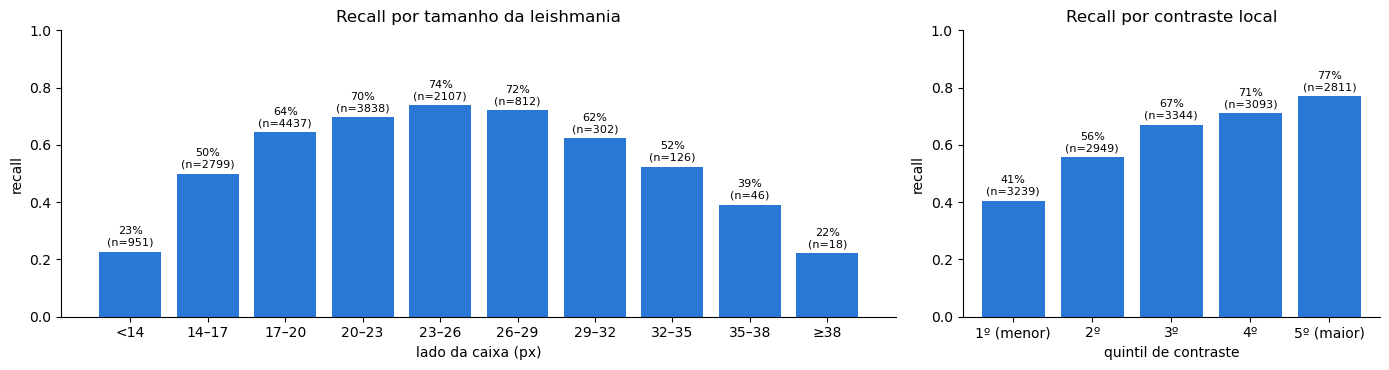

Leishmanias com menos de 17 px: 23.5%


Tipo de erro por faixa de tamanho (fração das anotadas da faixa):
categoria  FN: caixa mal localizada  FN: coberta pela máscara (>20%)  FN: cortada na borda do recorte  FN: não vista  FN: vista, conf. abaixo do limiar  GT detectada
tamanho                                                                                                                                                              
<14                           0.170                            0.000                            0.104          0.395                              0.103         0.227
14–17                         0.077                            0.001                            0.041          0.245                              0.136         0.500
17–20                         0.037                            0.001                            0.027          0.159                              0.132         0.645
20–23                         0.033                            0.000                            0.017   

recall       n
tamanho   <14          0.227   951.0
          14–17        0.500  2799.0
          17–20        0.645  4437.0
          20–23        0.696  3838.0
          23–26        0.738  2107.0
          26–29        0.722   812.0
          29–32        0.623   302.0
          32–35        0.524   126.0
          35–38        0.391    46.0
          ≥38          0.222    18.0
contraste 1º (menor)   0.406  3239.0
          2º           0.556  2949.0
          3º           0.671  3344.0
          4º           0.711  3093.0
          5º (maior)   0.771  2811.0

In [9]:
%matplotlib inline
# Tamanho e contraste medidos sempre na caixa ANOTADA ('GT detectada' ou 'FN'), não na prevista
gt = diag[diag.tipo.isin(['GT detectada', 'FN'])].copy()
# Faixas de 3 px; acima de 38 px há poucas leishmanias (~16), então ficam juntas
bordas = [0, 14, 17, 20, 23, 26, 29, 32, 35, 38, 100]
rotulos = ['<14'] + [f'{a}–{b}' for a, b in zip(bordas[1:-2], bordas[2:-1])] + ['≥38']
gt['tamanho'] = pd.cut(gt.lado, bordas, labels=rotulos)
gt['contraste_q'] = pd.qcut(gt.contraste, 5, labels=['1º (menor)', '2º', '3º', '4º', '5º (maior)'])
rec_tam = gt.groupby('tamanho', observed=True).apply(lambda x: pd.Series({'recall': (x.tipo == 'GT detectada').mean(), 'n': len(x)}), include_groups=False)
rec_con = gt.groupby('contraste_q', observed=True).apply(lambda x: pd.Series({'recall': (x.tipo == 'GT detectada').mean(), 'n': len(x)}), include_groups=False)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8), gridspec_kw={'width_ratios': [2, 1]})
for ax, tab, titulo, xl in [(axs[0], rec_tam, 'Recall por tamanho da leishmania', 'lado da caixa (px)'),
                            (axs[1], rec_con, 'Recall por contraste local', 'quintil de contraste')]:
    ax.bar(tab.index.astype(str), tab.recall, color='#2a78d6')
    for i, (v, n) in enumerate(zip(tab.recall, tab.n)):
        ax.text(i, v + 0.02, f'{v:.0%}\n(n={int(n)})', ha='center', fontsize=8)
    ax.set_ylim(0, 1); ax.set_title(titulo); ax.set_xlabel(xl); ax.set_ylabel('recall')
    ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(os.path.join(saida, 'figuras', 'recall_tamanho_contraste.png'), dpi=110); plt.show()
print(f"Leishmanias com menos de 17 px: {(gt.lado < 17).mean():.1%}")
# Tipo de erro por faixa de tamanho: as caixas grandes perdem por localização (IoU < 0,5)?
tipo_tam = pd.crosstab(gt.tamanho, gt.categoria, normalize='index').round(3)
print('Tipo de erro por faixa de tamanho (fração das anotadas da faixa):')
print(tipo_tam.to_string())
fn = gt[gt.tipo == 'FN']
print('\nIoU da melhor predição sobre as perdidas, por faixa (mediana):')
print(fn.groupby('tamanho', observed=True).iou_max.median().round(2).to_string())
pd.concat({'tamanho': rec_tam, 'contraste': rec_con}).round(3)

## Falsos positivos perto da máscara e sobre anotações `inside-macrophage`

In [10]:
fp = diag[diag.tipo.str.startswith('FP')]
tp = diag[diag.tipo == 'TP']
pd.DataFrame({
    'FP': [(fp.dist_mascara <= t).mean() for t in (4, 12, 24)],
    'FP conf ≥ 0,5': [(fp[fp.conf >= 0.5].dist_mascara <= t).mean() for t in (4, 12, 24)],
    'TP': [(tp.dist_mascara <= t).mean() for t in (4, 12, 24)]},
    index=['até 4 px da máscara', 'até 12 px', 'até 24 px']).round(3)

,FP,"FP conf ≥ 0,5",TP
até 4 px da máscara,0.029,0.017,0.026
até 12 px,0.072,0.060,0.077
até 24 px,0.131,0.126,0.137


In [11]:
print(f"FP sobre anotação inside-macrophage (IoU >= 0,3): {(fp.iou_inside >= 0.3).mean():.1%} de todos; "
      f"{(fp[fp.conf >= 0.5].iou_inside >= 0.3).mean():.1%} dos de confiança >= 0,5")

FP sobre anotação inside-macrophage (IoU >= 0,3): 3.0% de todos; 5.2% dos de confiança >= 0,5


## Galerias de exemplos

Cada quadro mostra 64×64 px em volta da caixa, ampliado 2×. Título: lâmina · confiança (ou tamanho, para FN).

In [12]:
def galeria(d, titulo, arquivo, n=24, colunas=8, cor=(255,0,0), ordem='conf', semente=0):
    sel = d.sort_values(ordem, ascending=False).head(n) if ordem else d.sample(min(n, len(d)), random_state=semente)
    linhas = int(np.ceil(len(sel) / colunas))
    fig, axs = plt.subplots(linhas, colunas, figsize=(colunas * 1.6, linhas * 1.75))
    for ax in np.ravel(axs): ax.axis('off')
    for ax, r in zip(np.ravel(axs), sel.itertuples()):
        img = cv2.imread(os.path.join(dir_mascarado, r.lamina, r.imagem))[:, :, ::-1].copy()
        x1, y1, x2, y2 = r.box.astype(int); cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
        cv2.rectangle(img, (x1, y1), (x2, y2), cor, 1)
        m = 32; pad = np.pad(img, ((m, m), (m, m), (0, 0)))
        ax.imshow(cv2.resize(pad[cy:cy + 2*m, cx:cx + 2*m], (128, 128), interpolation=cv2.INTER_NEAREST))
        ax.set_title(f"{r.lamina[-1:]}·{r.conf:.2f}" if r.conf == r.conf and r.conf > 0 else f"{r.lamina[-1:]}·{r.lado:.0f}px", fontsize=7)
    fig.suptitle(titulo, fontsize=10); plt.tight_layout(); plt.savefig(arquivo, dpi=90); plt.close()

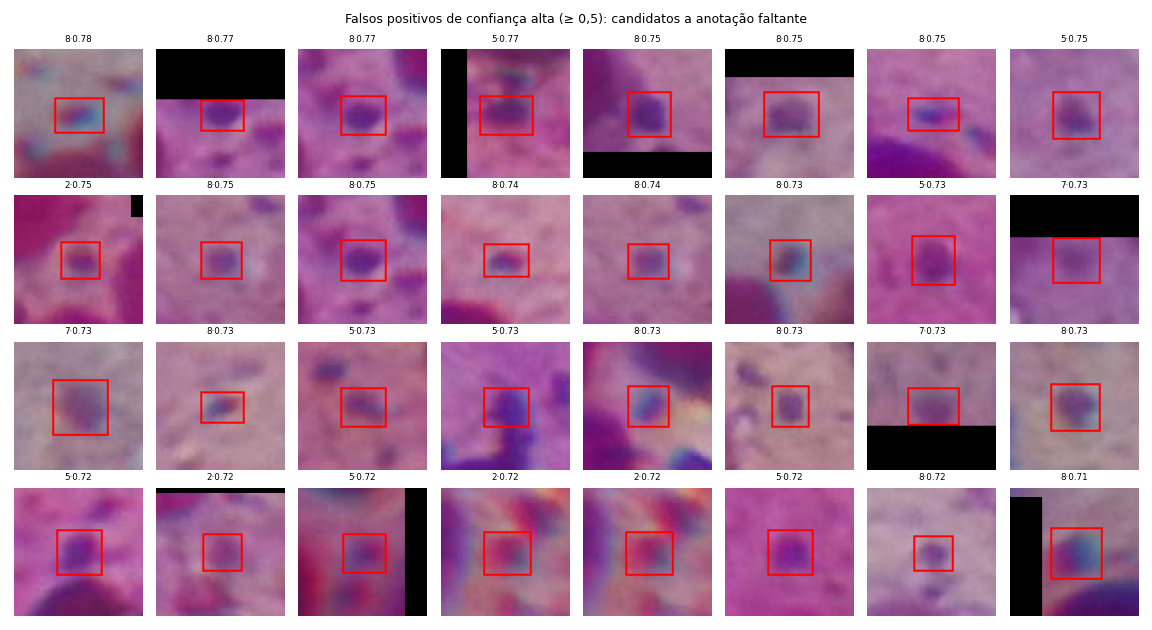

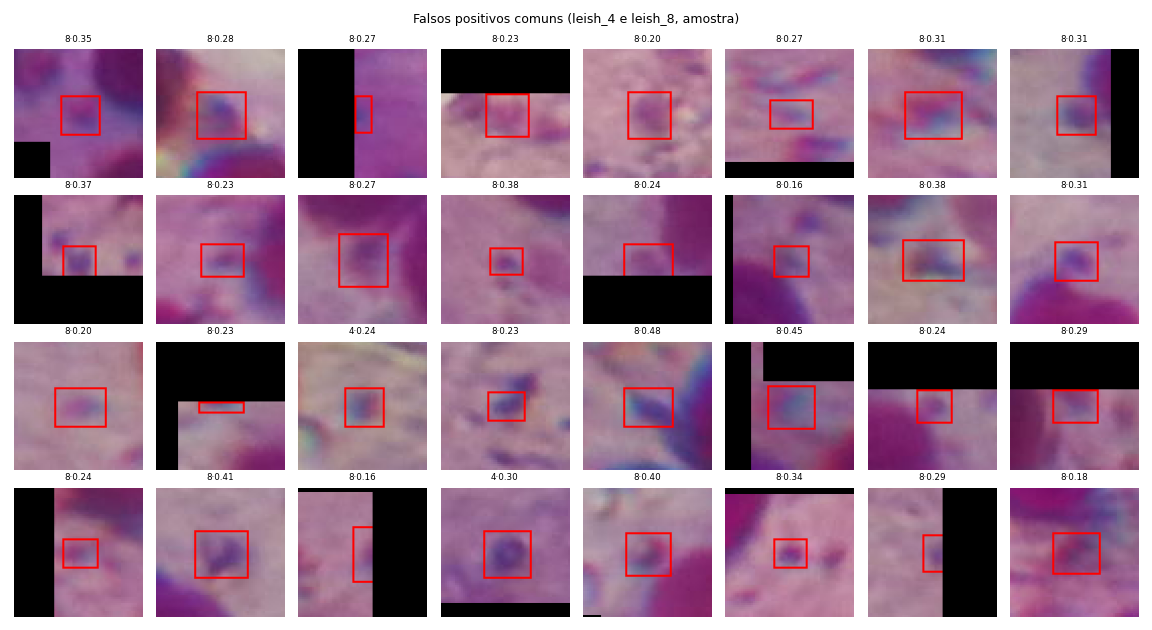

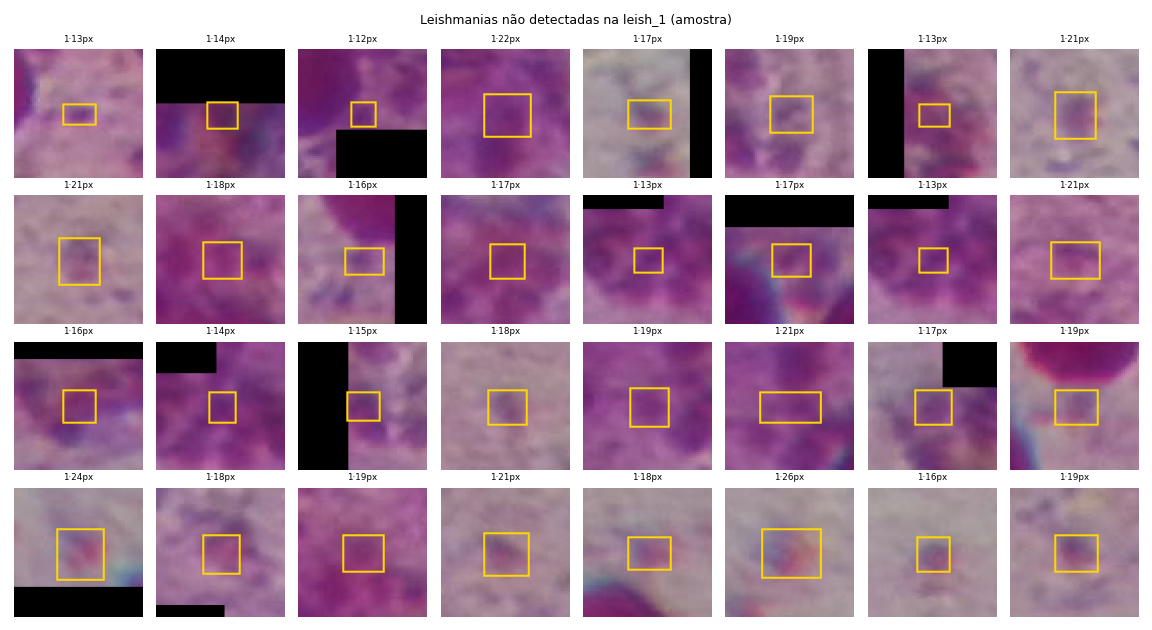

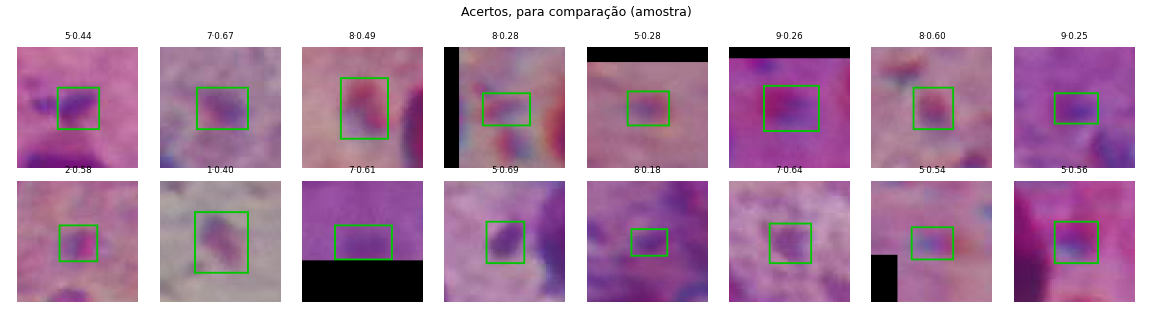

In [13]:
f = lambda nome: os.path.join(saida, 'figuras', nome)
galeria(diag[diag.categoria.str.startswith('FP: conf. alta')], 'Falsos positivos de confiança alta (≥ 0,5): candidatos a anotação faltante', f('fp_conf_alta.png'), n=32)
galeria(diag[(diag.categoria == 'FP: fundo, conf. baixa') & diag.lamina.isin(['leish_4', 'leish_8'])], 'Falsos positivos comuns (leish_4 e leish_8, amostra)', f('fp_fundo.png'), n=32, ordem=None)
galeria(diag[(diag.categoria == 'FN: não vista') & (diag.lamina == 'leish_1')], 'Leishmanias não detectadas na leish_1 (amostra)', f('fn_leish_1.png'), n=32, ordem=None, cor=(255, 215, 0))
galeria(diag[diag.tipo == 'TP'], 'Acertos, para comparação (amostra)', f('tp.png'), n=16, ordem=None, cor=(0, 200, 0))
from IPython.display import Image as Img, display
for nome in ['fp_conf_alta.png', 'fp_fundo.png', 'fn_leish_1.png', 'tp.png']:
    display(Img(f(nome)))

## Lista para revisão das anotações

Falsos positivos de confiança ≥ 0,5 sem anotação próxima. Se forem leishmanias reais, a anotação está faltando e o detector está sendo penalizado por acertar.

In [14]:
revisar = diag[diag.categoria.str.startswith('FP: conf. alta')].copy()
revisar[['x1', 'y1', 'x2', 'y2']] = np.vstack(revisar.box.values).round(0).astype(int)
revisar = revisar[['lamina', 'imagem', 'fold', 'conf', 'x1', 'y1', 'x2', 'y2', 'iou_inside']].sort_values(['lamina', 'conf'], ascending=[True, False])
revisar.to_csv(os.path.join(saida, 'fp_conf_alta_para_revisar.csv'), index=False)
print(f'{len(revisar)} caixas para revisar'); revisar.groupby('lamina').size()

1237 caixas para revisar


lamina
leish_1     10
leish_2    227
leish_3     23
leish_4      5
leish_5    469
leish_7     98
leish_8    397
leish_9      8
dtype: int64